Kruthi Jayendra, Sally Linkenauger, and Shawn June

# Survival Lab

We've looked at normal-linear regression and probit regression from a likelihood perspective, which yields two log-likelihoods:
$$
LL(\beta,\sigma) = - n \log( \sqrt{2\pi} ) - n \log(\sigma) - \frac{1}{2\sigma^2} \sum_{i=1}^n (y_i - x_i \beta)^2
$$
and
$$
LL(\beta) = \sum_{i=1}^N y_i \log(\Phi(x_i \cdot \beta/\sigma)) + (1-y_i) \log(1-\Phi(x_i \cdot \beta/\sigma)).
$$
This lab combines them by looking at **right-censored** survival data.

We are going to use the Metabric breast cancer dataset to predict how long someone survives after being treated for breast cancer. For the regressions that follow, include the following as numeric variables:

- 'Age at Diagnosis'
- 'Lymph nodes examined positive'
- 'Mutation Count'
- 'Tumor Size'

and the following as categorical variables (one-hot encode them):

- 'Chemotherapy'
- 'Hormone Therapy'
- 'Radio Therapy'
- 'Tumor Stage'

The outcome variable of interest is the log of `Overall Survival (Months)`, which we'll refer to as log-months.

1. Load the `./data/metabric.csv` data. Tabulate `Overall Survival Status` to see who is alive or dead at the time the study ends. Make a kernel density plot of `Overall Survival (Months)`, hued by `Overall Survival Status`, to see the difference between survival duration for those alive and those dead at the time the study ended. **Drop the observations for which `Tumor Stage` is zero.**
2. Use Scikit's `train_test_split` with a `test_size` of .2. There are two tempting -- but ultimately incorrect -- ways to handle the Survival Status issue:
    - Use the reported `Overall Survival (Months)` as the target variable
    - Drop everyone who is alive at the time the study ends
Run these flawed regressions and save the coefficients and test-set predictions. Explain clearly how the first option is an example of imputation and the second treats survival as missing data.
3. Derive the log-likelihood for a model where the normal density is used for log-months when the subject died during the study (and log-months is observed, as in linear-normal regression), and the survival probability based on the Normal distribution is used when the patient is alive when the study ends (and log-months is a latent variable, as in a binary probit).
4. We want to estimate the model in part 3. You can do this with the `lifelines` package's `LogNormalAFTFitter`, or use the code chunk below to extend StatsModels to estimate this kind of model.
5. Compare the coefficients and test-set predictions (be careful to keep an eye on the censoring) for the censored MLE and the two linear models. Can you identify any groups who receive systematically biased predictions from the imputation and missing data approaches? 

<font color = "burntorange">

### Question 3: Model derivation
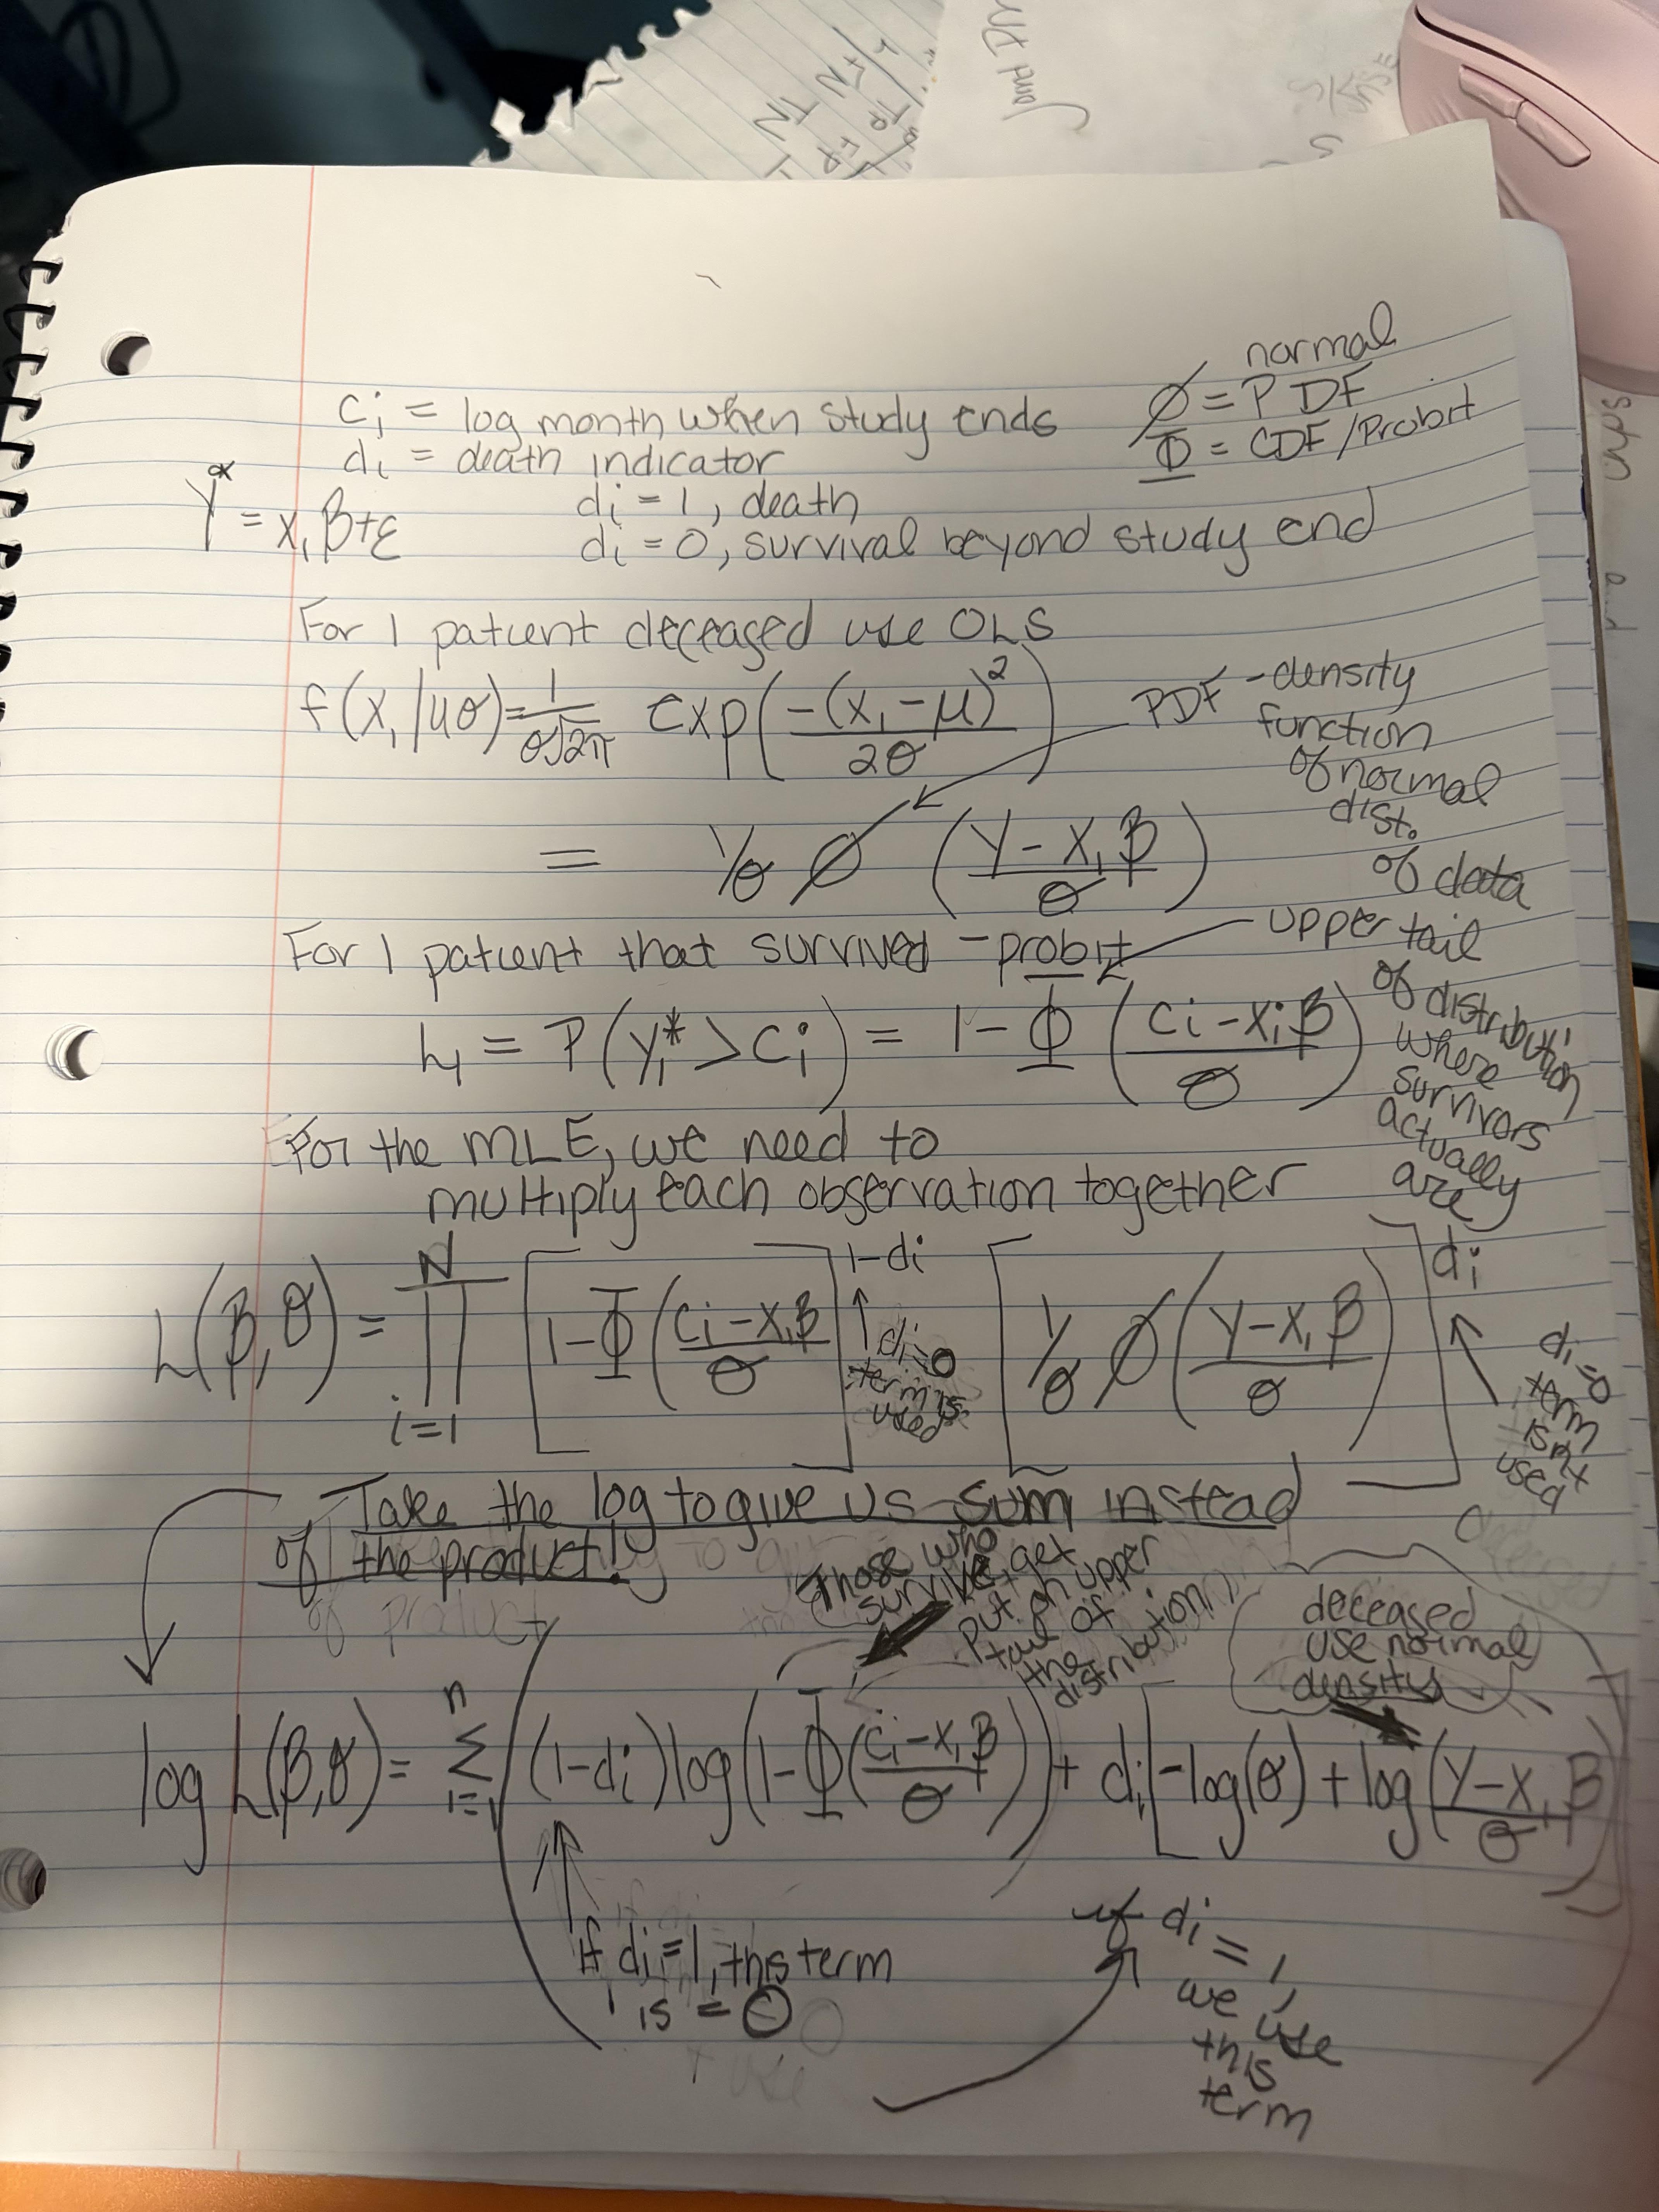

In [1]:
/Users/shawnjune/Downloads/IMG_1471.jpeg

NameError: name 'Users' is not defined

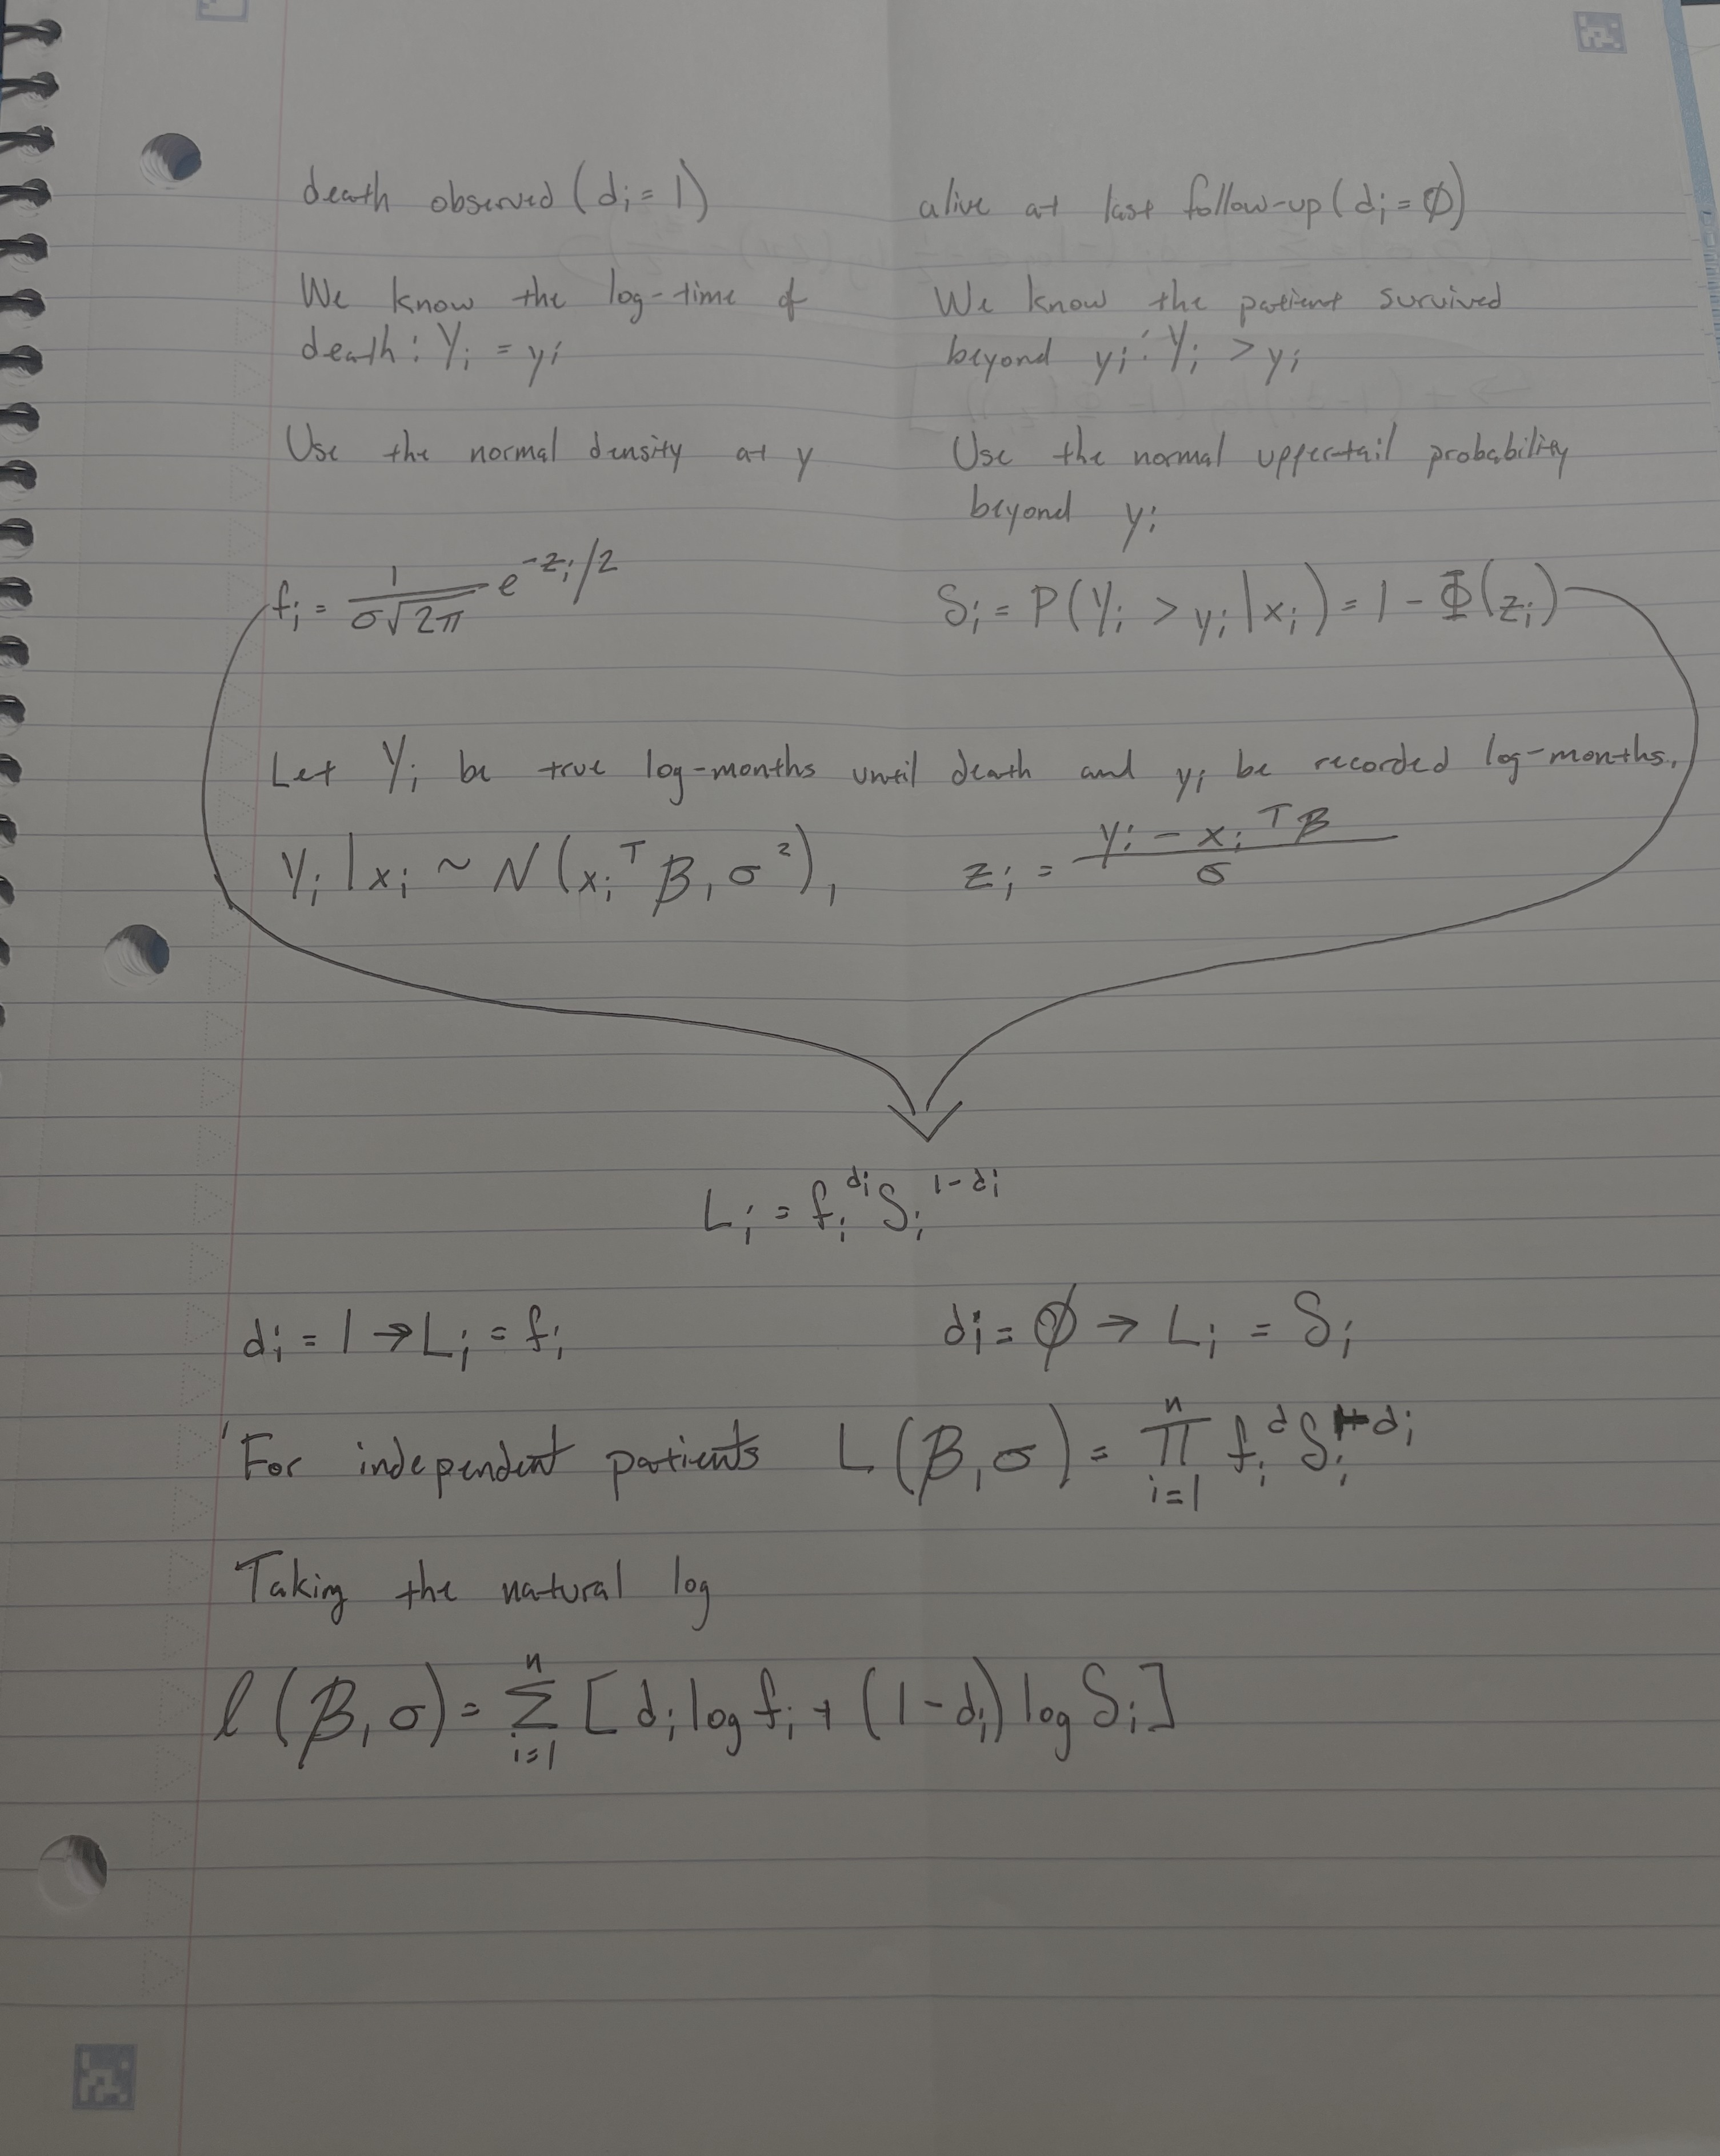

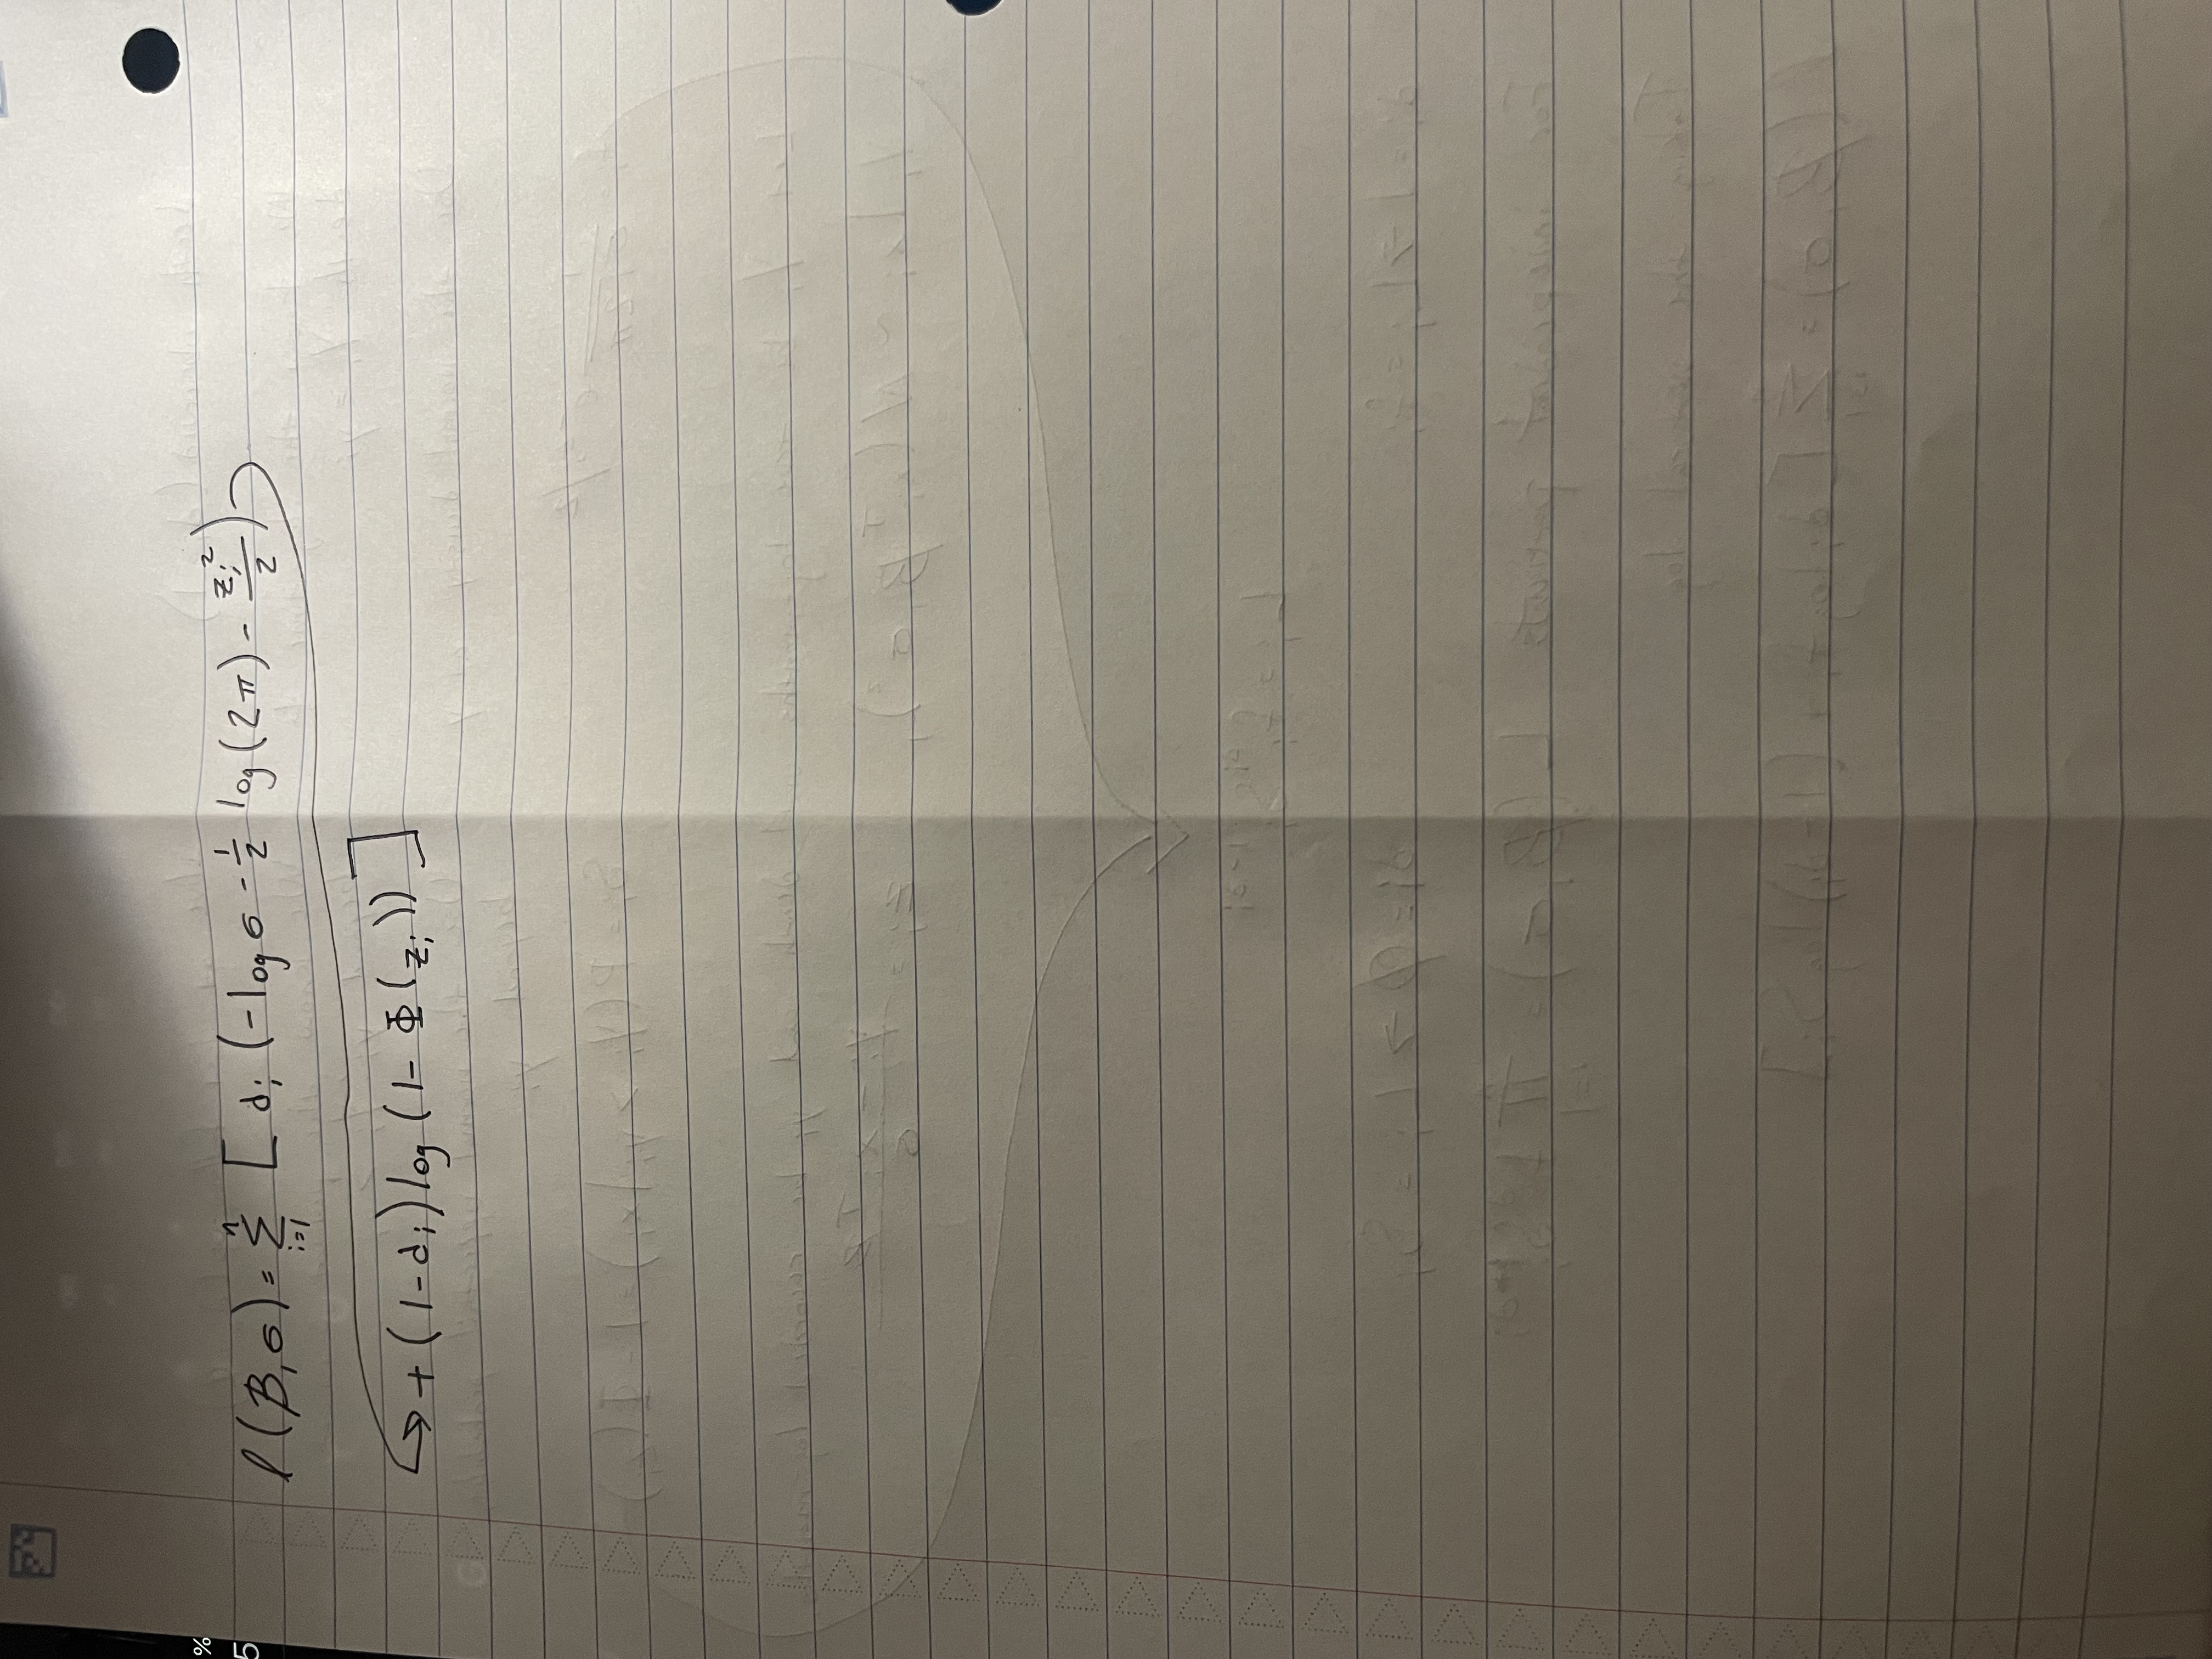

In [8]:
from IPython.display import Image, display

display(Image(filename="/Users/shawnjune/Downloads/re/IMG_1472.jpeg"))

In [1]:
#class CensoredNormalMLE(GenericLikelihoodModel):
#    def __init__(self, endog, exog, event):
#        super().__init__(endog, exog, extra_params_names=["log_sigma"])
 #       self.event = np.asarray(event)

  #  def nloglikeobs(self, params):
   #     beta, log_sigma = params[:-1], params[-1]
    #    sigma = np.exp(log_sigma)
     #`   z = (self.endog - self.exog @ beta) / sigma
       # ll_dead = norm.logpdf(z) - log_sigma
        #ll_alive = norm.logsf(z)
        #return -np.where(self.event == 1, ll_dead, ll_alive)

#start = np.r_[ols_all.params, np.log(np.sqrt(np.mean(ols_all.resid ** 2)))]

#model = CensoredNormalMLE(y_train, X_train, train["event"])
#mle = model.fit(start_params=start, method="bfgs", maxiter=1000, disp=False)

#print("Converged:", mle.mle_retvals["converged"])
#print(mle.summary())

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns   
from sklearn.base import clone
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, GroupKFold, GridSearchCV
from sklearn.metrics import log_loss, confusion_matrix, accuracy_score
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler, SplineTransformer
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.metrics import mean_squared_error, r2_score
import plotly.express as px
import plotly.graph_objects as go




<font color = "burntorange">

### Question 1 (drop Stage 0 and KDE)

In [3]:
#View data
mb= pd.read_csv("metabric.csv")

print(mb.columns)

mb.head()

Index(['Age at Diagnosis', 'Type of Breast Surgery', 'Cancer Type',
       'Chemotherapy', 'Hormone Therapy', 'Lymph nodes examined positive',
       'Mutation Count', 'Nottingham prognostic index',
       'Overall Survival (Months)', 'Overall Survival Status', 'Radio Therapy',
       'TMB (nonsynonymous)', 'Tumor Size', 'Tumor Stage'],
      dtype='object')


,Age at Diagnosis,Type of Breast Surgery,Cancer Type,Chemotherapy,Hormone Therapy,Lymph nodes examined positive,Mutation Count,Nottingham prognostic index,Overall Survival (Months),Overall Survival Status,Radio Therapy,TMB (nonsynonymous),Tumor Size,Tumor Stage
0,43.19,BREAST CONSERVING,Breast Cancer,NO,YES,0.0,2.0,4.020,84.633333,0:LIVING,YES,2.615035,10.0,1.0
1,48.87,MASTECTOMY,Breast Cancer,YES,YES,1.0,2.0,4.030,163.700000,1:DECEASED,NO,2.615035,15.0,2.0
2,47.68,MASTECTOMY,Breast Cancer,YES,YES,3.0,1.0,4.050,164.933333,0:LIVING,YES,1.307518,25.0,2.0
3,76.97,MASTECTOMY,Breast Cancer,YES,YES,8.0,2.0,6.080,41.366667,1:DECEASED,YES,2.615035,40.0,2.0
4,78.77,MASTECTOMY,Breast Cancer,NO,YES,0.0,4.0,4.062,7.800000,1:DECEASED,YES,5.230071,31.0,4.0


In [4]:

#Find out how many patients have Tumor Stage 0
print(mb[mb["Tumor Stage"] == 0]["Overall Survival (Months)"].count())

#Summarize numerical variables by Overall Survival Status with Tumor Stage = 0
filtered_mb = mb[mb["Tumor Stage"] == 0]
filtered_mb.select_dtypes(include="number").groupby(filtered_mb["Overall Survival Status"]).agg(
    ["count", "mean", "std", "min", "max", "median"]
)




2


Age at Diagnosis                                  \
                                   count   mean        std    min    max   
Overall Survival Status                                                    
0:LIVING                               2  50.66  12.275374  41.98  59.34   

                               Lymph nodes examined positive                 \
                        median                         count mean  std  min   
Overall Survival Status                                                       
0:LIVING                 50.66                             2  0.0  0.0  0.0   

                         ... Tumor Size                    Tumor Stage       \
                         ...        std   min   max median       count mean   
Overall Survival Status  ...                                                  
0:LIVING                 ...  16.970563  11.0  35.0   23.0           2  0.0   

                                               
                         std  min  max median  
Overall Survival Status                        
0:LIVING                 0.0  0.0  0.0    0.0  

[1 rows x 48 columns]

In [5]:
#Summarize numerical variables by Overall Survival Status without Tumor Stage = 0

filtered_mb = mb[(mb['Tumor Stage'] != 0)]
filtered_mb.select_dtypes(include="number").groupby(filtered_mb["Overall Survival Status"]).agg(
    ["count", "mean", "std", "min", "max", "median"]
)

Age at Diagnosis                                     \
                                   count       mean       std    min    max   
Overall Survival Status                                                       
0:LIVING                             573  56.023560  11.20736  26.72  85.21   
1:DECEASED                           768  64.036979  13.13640  21.93  96.29   

                               Lymph nodes examined positive            \
                        median                         count      mean   
Overall Survival Status                                                  
0:LIVING                 56.03                           573  1.109948   
1:DECEASED               65.81                           768  2.424479   

                                        ... Tumor Size                     \
                              std  min  ...        std  min    max median   
Overall Survival Status                 ...                                 
0:LIVING                 2.627874  0.0  ...  11.211610  1.0   99.0   20.0   
1:DECEASED               4.486634  0.0  ...  16.562743  1.0  180.0   25.0   

                        Tumor Stage                                       
                              count      mean       std  min  max median  
Overall Survival Status                                                   
0:LIVING                        573  1.623037  0.586229  1.0  4.0    2.0  
1:DECEASED                      768  1.845052  0.623906  1.0  4.0    2.0  

[2 rows x 48 columns]

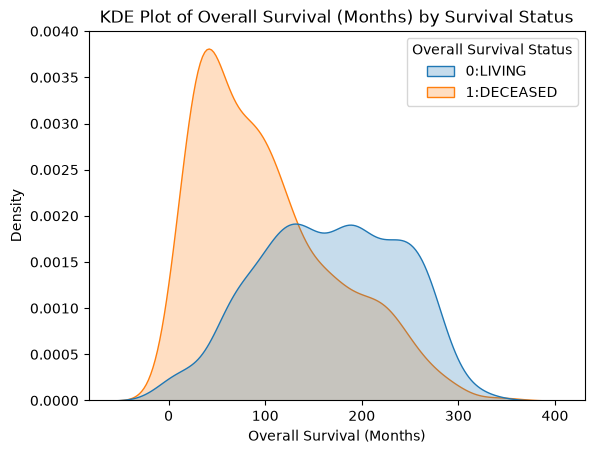

In [6]:

#plot kde for Overall Survival (Months) by Overall Survival Status

sns.kdeplot(filtered_mb, x= filtered_mb["Overall Survival (Months)"], fill=True, color="blue", hue = filtered_mb["Overall Survival Status"])
plt.title("KDE Plot of Overall Survival (Months) by Survival Status")
plt.show()



<font color = "burntorange">

<em>There are two tempting -- but ultimately incorrect -- ways to handle the Survival Status issue:
    - Use the reported `Overall Survival (Months)` as the target variable
    - Drop everyone who is alive at the time the study ends 
Explain clearly how the first option is an example of imputation and the second treats survival as missing data.</em>

This problem that we have with our data is that of <b>construct validity</b>.  The question is "Does our measure reflect the underlying construct that we think that it does?"  In this case, our construct is the length of time that cancer patients lived following the diagnosis of cancer; the goal is to predict survival on new patients and identify the parameters that are associated with longer Overall Survival times. 

 Our measure, Overall Survival, only provides information about whether individuals that died during the timeline of the study.  For individuals that survived the duration of the study, we only have the time in which they were diagnosed to the end of the study listed as their Overall Survival.  In the context of the data for the surviving individuals, this number insinuates by the nature of the measure that those patients only lived that length of the time rather than survived a longer timeline extending past the duration of the study. 

 Not all survivors have longer Overall Survival times than those patients who died during the study. Patients enter the study when they are diagnosed with cancer, so they do not all enter the study at the same time but at random times through the study. This introduces a scale problem, because different patients that survived will have a different Overall survival based on when they joined the study.  Hence, survivors are not likely to have an Overall Survival that is the entire duration of the study and therefore, longer than those who are deceased. Consider the possibility that a patient who entered the study 2 months before the end of the study and lived past the end only has a survival time of two months, whereas a patient who was diagnosed and died two months later within the study window would have the same survival time.

 This dependent measure means that our model is training on outcome data that does not accurately operationalize the variable we are trying to measure.

<b>Imputation:</b>
 We are operationalizing the time from diagnosis to death as the Overall Survival time.  For deceased patients, we have those complete observations. However, for the participants that lived past the length of the study, we only have the time from diagnosis to the end of the study as their Overall Survival time.   For those living patients, if we used their time from diagnosis to study end, we can consider this imputation, because we are using the length of their participation in the study as a proxy for their survival time (time to deceased), when we really are not sure what their actual Overall Survival length is, we just know that it is longer than the length of the study.  We know the number representing their Overall Survival is less than their actual Overall Survival.  Basically, everyone who survived is assumed dead when the study ends.
     

As the individuals that survived have survivor rates longer than the end of the study, imputing the length of their participation undershoots their actual survival time and biases predictions from models trained on this imputation.  This imputation creates an artificial, misleading outcome value for almost half of our participants (43% survived the duration of the study).  

  

<b>Missing Data:</b>
In this case, we are dropping the individuals that survived the duration of the study, or put simply, ignoring their presence as we would data that was incomplete or missing from the data set.  The reason to justify this would be to presume that we do not have the Overall survival durations for these  patients in the same way we do for those who died during the study (diagnosis to deceased).  Consequently, their time to deceased is missing and unknown.  As a result, in this case, we are refining our population that we are trying to predict to only those that died during the study window. The model cannot generalize beyond that.

To ignore missing data, we need to presume that missingness is not systematic but rather completely random.  The missingness here is systematic in that these participants likely had longer Overall survival durations. Additionally, the model is not trained on 43% of the data in which there were successful outcomes. The model is trained only on patients that died during the study window. Therefore, we are restricting the range of possible outcomes. Parameters that might have indicated successful outcomes will not have the outcome data necessary to fully predict those outcomes, and hence, their impact will be suppressed. Overall, not including this data may also defeat the purpose of the study, which I am presuming is the identification of variables that improve/worsen patient outcomes and to predict patient outcomes based on these variables. Survival is an outcome. That said, including data would also be including data that is not a true reflection of these participants overall survival.


<b>What these two will probably do to the model?</b>

I am not entirely sure.  I do not see how any parameters that could actually explain survival in cancer patients could explain variability in a outcome variable that is inconsistent and full of mostly arbitrary noise.   In the case of imputation, any consistent signal in the Overall Survival outcome is masked by likely conflicting or inconsistent signals from those that survived past the study end.  Consequently, I doubt the parameters will be able to grasp onto much. The models predictions based on this measure should be lower than the actual population values, because we know that they are training on data at either the lower range of Outcome Survival (DM) or Outcome Survival values that are less than they actually are (IM).

In the case of treating them as missing data, we are omitting participants who had successful outcomes.  Parameters rely on both ends of the spectrum to establish a relationship.  Also, time of diagnosis is somewhat arbitrary, and is not indicative of cancer progression, so the Overall Survival length is somewhat suspect as a measure even for those that remain in the data.


<font color ="burntorange">

### Question 2, part 1: Drop Missing and OLS

In [7]:
filtered_mb["survival"] = [1 if status == "1:DECEASED" else 0 for status in filtered_mb["Overall Survival Status"]]
print(filtered_mb["survival"].value_counts())
#mb_dropMissing = filtered_mb[(filtered_mb['survival'] == 1)]

#mb_dropMissing["survival"].value_counts()

survival
1    768
0    573
Name: count, dtype: int64


C:\Users\sally\AppData\Local\Temp\ipykernel_39524\288348093.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_mb["survival"] = [1 if status == "1:DECEASED" else 0 for status in filtered_mb["Overall Survival Status"]]


In [8]:
#Group categorical and numerical variables for linear regression with only deceased patients
y_full = np.log(filtered_mb["Overall Survival (Months)"])
X_full = filtered_mb[["Chemotherapy", "Hormone Therapy", "Radio Therapy", "Tumor Stage",
                    "Age at Diagnosis", "Lymph nodes examined positive", "Mutation Count", "Tumor Size"]]

cats = ["Chemotherapy", "Hormone Therapy", "Radio Therapy", "Tumor Stage"]

nums = ["Age at Diagnosis", "Lymph nodes examined positive", "Mutation Count", "Tumor Size"]


In [ ]:
#Annoying train test split with keeping survivors in test when the indexes get shuffled.  I 

status_full = filtered_mb["survival"]

X_train_full, X_test_full, y_train_full, y_test_full, status_train, status_test = train_test_split(
    X_full, y_full, status_full, test_size=0.2, random_state=42
)

deceased_mask_train = (status_train == 1)
X_train_dm = X_train_full[deceased_mask_train]
y_train_dm = y_train_full[deceased_mask_train]

X_test_dm = X_test_full
y_test_dm = y_test_full


preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), nums),
        ("cat", OneHotEncoder(drop="first"), cats)
    ]
)

In [29]:
#Create pipeline/run pipeline

linear_regression_dm = LinearRegression()
pipeline_dm = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", linear_regression_dm)
])


pipeline_dm.fit(X_train_dm, y_train_dm)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformer

In [30]:
#Show coefficients

print("Intercept:", linear_regression_dm.intercept_)

coef = pd.DataFrame({
    "Feature": preprocessor.get_feature_names_out(),
    "Coefficient": linear_regression_dm.coef_
})

coef



Intercept: 4.416359933220116


,Feature,Coefficient
0,num__Age at Diagnosis,-0.038820
1,num__Lymph nodes examined positive,-0.123615
2,num__Mutation Count,0.042183
3,num__Tumor Size,-0.027466
4,cat__Chemotherapy_YES,-0.393093
5,cat__Hormone Therapy_YES,0.242348
6,cat__Radio Therapy_YES,0.039192
7,cat__Tumor Stage_2.0,-0.223816
8,cat__Tumor Stage_3.0,-0.552826
9,cat__Tumor Stage_4.0,-1.049910


In [34]:
#plot of training data predicted vs actual

import plotly.graph_objects as go

fig = px.scatter(x=y_train_dm, y=pipeline_dm.predict(X_train_dm),
                 labels={"x": "Actual Overall Survival (Log Months)", "y": "Predicted Overall Survival (Log Months)"})

fig.add_trace(go.Scatter(
    x=[min(y_train_dm), max(y_train_dm)], 
    y=[min(y_train_dm), max(y_train_dm)], 
    mode="lines", 
    name="Accurate Prediction"
))

fig.update_layout(title="Predicted versus Actual Overall Survival (Log Months) Equal Axes")
fig.update_xaxes(range=[min(y_train_dm)-0.2, max(y_train_dm)+0.2])
fig.update_yaxes(range=[min(y_train_dm)-0.2, max(y_train_dm)+0.2])

fig.show()

In [35]:
#plot of test data predicted vs actual

fig = px.scatter(x=y_test_dm, y=pipeline_dm.predict(X_test_dm),
                 labels={"x": "Actual Overall Survival (Log Months)", "y": "Predicted Overall Survival (Log Months)"})

fig.add_trace(go.Scatter(
    x=[min(y_test_dm), max(y_test_dm)],
    y=[min(y_test_dm), max(y_test_dm)],
    mode="lines",
    name="Correct Prediction"
))

fig.update_layout(title="Drop Missing: Predicted vs Actual (Test Set)")
fig.update_xaxes(range=[min(y_test_dm)-0.2, max(y_test_dm)+0.2])
fig.update_yaxes(range=[min(y_test_dm)-0.2, max(y_test_dm)+0.2])
fig.show()

In [33]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
r2_train = r2_score(y_train_dm, pipeline_dm.predict(X_train_dm))
mae_train = mean_absolute_error(y_train_dm, pipeline_dm.predict(X_train_dm))
rmse_train = np.sqrt(mean_squared_error(y_train_dm, pipeline_dm.predict(X_train_dm)))
print({"Model": "Drop Missing (Train)", "R2": r2_train, "MAE": mae_train, "RMSE": rmse_train})

r2 = r2_score(y_test_dm, pipeline_dm.predict(X_test_dm))
mae = mean_absolute_error(y_test_dm, pipeline_dm.predict(X_test_dm))
rmse = np.sqrt(mean_squared_error(y_test_dm, pipeline_dm.predict(X_test_dm)))
print({"Model": "Drop Missing (Test)", "R2": r2, "MAE": mae, "RMSE": rmse})

{'Model': 'Drop Missing (Train)', 'R2': 0.15182610841682942, 'MAE': 0.6419814361838325, 'RMSE': np.float64(0.8386529756118312)}
{'Model': 'Drop Missing (Test)', 'R2': -0.04902586464831504, 'MAE': 0.6460002353693199, 'RMSE': np.float64(0.8279446582444699)}


<font color = "burntorange">

### Question 2, part 2: Imputation and OLS

In [15]:
#Create matrices

#Group categorical and numerical variables for linear regression with only deceased patients
y_im = np.log(filtered_mb["Overall Survival (Months)"])
X_im = filtered_mb[["Chemotherapy", "Hormone Therapy", "Radio Therapy", "Tumor Stage",
                    "Age at Diagnosis", "Lymph nodes examined positive", "Mutation Count", "Tumor Size"]]

cats = ["Chemotherapy", "Hormone Therapy", "Radio Therapy", "Tumor Stage"]

nums = ["Age at Diagnosis", "Lymph nodes examined positive", "Mutation Count", "Tumor Size"]


In [16]:
#test train split and preprocess

X_train_im, X_test_im, y_train_im, y_test_im = train_test_split(X_im, y_im, test_size=0.2, random_state=42)



preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), nums),
        ("cat", OneHotEncoder(drop="first"), cats)
    ]
)

In [17]:
#Create pipeline/run pipeline

linear_regression_im = LinearRegression()
pipeline_im = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", linear_regression_im)
])
pipeline_im.fit(X_train_im, y_train_im)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformer

In [18]:
#Show coefficients

print("Intercept:", linear_regression_im.intercept_)

coef = pd.DataFrame({
    "Feature": preprocessor.get_feature_names_out(),
    "Coefficient": linear_regression_im.coef_
})

coef

Intercept: 4.6455685326764025


,Feature,Coefficient
0,num__Age at Diagnosis,-0.112128
1,num__Lymph nodes examined positive,-0.146104
2,num__Mutation Count,0.025041
3,num__Tumor Size,-0.052325
4,cat__Chemotherapy_YES,-0.219118
5,cat__Hormone Therapy_YES,0.086354
6,cat__Radio Therapy_YES,0.120239
7,cat__Tumor Stage_2.0,-0.187168
8,cat__Tumor Stage_3.0,-0.405198
9,cat__Tumor Stage_4.0,-0.707348


In [19]:
#plot of training data predicted vs actual

fig = px.scatter(x=y_train_im, y=pipeline_im.predict(X_train_im),
                 labels={"x": "Actual Overall Survival (Months)", "y": "Predicted Overall Survival (Months)"})

fig.add_trace(go.Scatter(
    x=[min(y_train_im), max(y_train_im)], 
    y=[min(y_train_im), max(y_train_im)], 
    mode="lines", 
    name="Accurate Prediction"
))

fig.update_layout(title="Predicted versus Actual Overall Survival (Months) Imputation *Training*")
fig.update_xaxes(range=[min(y_train_im)-0.2, max(y_train_im)+0.2])
fig.update_yaxes(range=[min(y_train_im)-0.2, max(y_train_im)+0.2])

fig.show()

In [20]:
#graph of test data predicted vs actual
fig = px.scatter(x=y_test_im, y=pipeline_im.predict(X_test_im),
                 labels={"x": "Actual Overall Survival (Log Months)", "y": "Predicted Overall Survival (Log Months)"})

fig.add_trace(go.Scatter(
    x=[min(y_test_im), max(y_test_im)],
    y=[min(y_test_im), max(y_test_im)],
    mode="lines",
    name="Correct Prediction"
))

fig.update_layout(title="Imputation: Predicted vs Actual (Test Set)")
fig.update_xaxes(range=[min(y_test_im)-0.2, max(y_test_im)+0.2])
fig.update_yaxes(range=[min(y_test_im)-0.2, max(y_test_im)+0.2])
fig.show()

In [21]:
#Train stats
r2_train = r2_score(y_train_im, pipeline_im.predict(X_train_im))
mae_train = mean_absolute_error(y_train_im, pipeline_im.predict(X_train_im))
rmse_train = np.sqrt(mean_squared_error(y_train_im, pipeline_im.predict(X_train_im)))
print({"Model": "Imputation (Train)", "R2": r2_train, "MAE": mae_train, "RMSE": rmse_train})
#Test stats

r2 = r2_score(y_test_im, pipeline_im.predict(X_test_im))
mae = mean_absolute_error(y_test_im, pipeline_im.predict(X_test_im))
rmse = np.sqrt(mean_squared_error(y_test_im, pipeline_im.predict(X_test_im)))
print(f"{{'Model': 'Imputation (Test)', 'R2': {r2}, 'MAE': {mae}, 'RMSE': {rmse}}}")



{'Model': 'Imputation (Train)', 'R2': 0.12098977742544104, 'MAE': 0.6253390834167217, 'RMSE': np.float64(0.8361044960706718)}
{'Model': 'Imputation (Test)', 'R2': 0.09996069647903849, 'MAE': 0.5857984545431522, 'RMSE': 0.7669003709495941}


<font color = "burntorange">

### Overall Interpretation of these Models

Both of these models have pretty flat predictions (e.g., the predictions are in a small range of the outcome variable) with very little variation.  This trend suggests that the models' parameters are having difficulty explaining the variation in the data.  For both models (i.e.,the missing data with the restricted range and the imputation with the misleading outcome values for survivors), they seem to predict mostly the mean of the outcome measure with very few predictions spanning the high and low areas of the actual outcome range.

The models only explain around 10% of the variance in Overall Survival. An RMSE of 1 on standardized data is merely predicting the mean; below values indicate a better fit.  These models are all pretty close to 1 RMSE.

Specifically, the R2 for the DM model is absolutely terrible.  Guessing the mean of the test data for every data point has a better outcome (R2 =0) than our DM model on the test data (R2 = -0.049).  Presumably, the DM model trained on data that dropped survivors and then tested on data that included not only survivors, but survivors' misleading outcomes. 

Imputation (Train): R2: 0.121 

                    Root mean squared error: 0.836

Imputation (Test):  R2: 0.0999

                    Root mean squared error: 0.767


Drop Missing (Train): R2: 0.1518

                      Root mean squared error: 0.838

Drop Missing (Test):  R2: -0.049

                      Root mean squared error: 0.827

<font color = "burntorange">

### Censored MLE 

In [22]:

from lifelines import LogNormalAFTFitter

model_data_AFT = filtered_mb[cats + nums + ["survival", "Overall Survival (Months)"]].copy()
encoded_df_AFT = pd.get_dummies(model_data_AFT, drop_first=True, dtype=float)


encoded_df_train_AFT, encoded_df_test_AFT = train_test_split(encoded_df_AFT, test_size=0.2, random_state=42)


scaler = StandardScaler()
encoded_df_train_AFT[nums] = scaler.fit_transform(encoded_df_train_AFT[nums])
encoded_df_test_AFT[nums] = scaler.transform(encoded_df_test_AFT[nums])

aft = LogNormalAFTFitter()
aft.fit(encoded_df_train_AFT, duration_col='Overall Survival (Months)', event_col='survival')
aft.print_summary()

<lifelines.LogNormalAFTFitter: fitted with 1072 total observations, 457 right-censored observations>
             duration col = 'Overall Survival (Months)'
                event col = 'survival'
   number of observations = 1072
number of events observed = 615
           log-likelihood = -3853.50
         time fit was run = 2026-11-18 20:39:08 UTC

---
                                      coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
param  covariate                                                                                                                      
mu_    Age at Diagnosis              -0.29      0.75      0.04           -0.37           -0.20                0.69                0.82
       Chemotherapy_YES              -0.28      0.75      0.12           -0.51           -0.06                0.60                0.95
       Hormone Therapy_YES            0.25      1.29      0.08            0.09            0.42                1.09                1.52
       Lymph nodes examined positive -0.21      0.81      0.04           -0.29           -0.13                0.75                0.87
       Mutation Count                -0.07      0.94      0.04           -0.14            0.00                0.87                1.00
       Radio Therapy_YES              0.22      1.24      0.08            0.06            0.37                1.06                1.45
       Tumor Size                    -0.12      0.89      0.04           -0.20           -0.03                0.82                0.97
       Tumor Stage                   -0.29      0.75      0.08           -0.45           -0.14                0.64                0.87
       Intercept                      5.31    202.42      0.14            5.03            5.59              152.51              268.67
sigma_ Intercept                      0.08      1.09      0.03            0.02            0.14                1.02                1.15

                                      cmp to     z      p  -log2(p)
param  covariate                                                   
mu_    Age at Diagnosis                 0.00 -6.57 <0.005     34.17
       Chemotherapy_YES                 0.00 -2.44   0.01      6.09
       Hormone Therapy_YES              0.00  3.05 <0.005      8.77
       Lymph nodes examined positive    0.00 -5.35 <0.005     23.46
       Mutation Count                   0.00 -1.83   0.07      3.89
       Radio Therapy_YES                0.00  2.67   0.01      7.03
       Tumor Size                       0.00 -2.77   0.01      7.50
       Tumor Stage                      0.00 -3.77 <0.005     12.57
       Intercept                        0.00 36.76 <0.005    980.44
sigma_ Intercept                        0.00  2.77   0.01      7.47
---
Concordance = 0.67
AIC = 7726.99
log-likelihood ratio test = 191.75 on 8 df
-log2(p) of ll-ratio test = 121.11

In [23]:
medians = aft.predict_median(encoded_df_train_AFT)

actual_log = np.log(encoded_df_train_AFT["Overall Survival (Months)"])
predicted_log = np.log(medians)

combined = pd.concat([actual_log, predicted_log])
lo = np.percentile(combined, 1)
hi = np.percentile(combined, 99)

fig = px.scatter(x=actual_log, y=predicted_log,
                 labels={"x": "Actual Overall Survival (Log months)", "y": "Predicted Overall Survival (Log months)"})

fig.add_trace(go.Scatter(
    x=[lo, hi],
    y=[lo, hi],
    mode="lines",
    name="Correct Prediction"
))

fig.update_layout(title="Censored MLE: Predicted versus Actual Overall Survival (Log Months)")
fig.update_xaxes(range=[lo-0.2, hi+0.2])
fig.update_yaxes(range=[lo-0.2, hi+0.2])
fig.show()


In [24]:
medians_test = aft.predict_median(encoded_df_test_AFT)

actual_log_test = np.log(encoded_df_test_AFT["Overall Survival (Months)"])
predicted_log_test = np.log(medians_test)

combined = pd.concat([actual_log_test, predicted_log_test])
lo = np.percentile(combined, 1)
hi = np.percentile(combined, 99)

fig = px.scatter(x=actual_log_test, y=predicted_log_test,
                 labels={"x": "Actual Overall Survival (Log Months)", "y": "Predicted Overall Survival (Log Months)"})

fig.add_trace(go.Scatter(
    x=[lo, hi],
    y=[lo, hi],
    mode="lines",
    name="Perfect Prediction"
))

fig.update_layout(title="Censored MLE: Predicted versus Actual Overall Survival (Log Months) — Test Set")
fig.update_xaxes(range=[lo-0.2, hi+0.2])
fig.update_yaxes(range=[lo-0.2, hi+0.2])
fig.show()

In [25]:
from plotly.subplots import make_subplots
import plotly.graph_objects as go

pred_dm = pipeline_dm.predict(X_test_dm)
pred_im = pipeline_im.predict(X_test_im)

medians_test = aft.predict_median(encoded_df_test_AFT)
actual_log_test = np.log(encoded_df_test_AFT["Overall Survival (Months)"])
predicted_log_test = np.log(medians_test)

all_values = pd.concat([
    pd.Series(y_test_dm), pd.Series(pred_dm),
    pd.Series(y_test_im), pd.Series(pred_im),
    actual_log_test, predicted_log_test
])
lo, hi = np.percentile(all_values, 1), np.percentile(all_values, 99)

fig = make_subplots(
    rows=1, cols=3,
    subplot_titles=("Drop Missing", "Imputation", "Censored MLE")
)

panels = [
    (y_test_dm, pred_dm, "Drop Missing", 1),
    (y_test_im, pred_im, "Imputation", 2),
    (actual_log_test, predicted_log_test, "Censored MLE", 3),
]

for actual, predicted, name, col in panels:
    actual_arr = np.asarray(actual)
    predicted_arr = np.asarray(predicted)

    # Fit a simple line: predicted = slope * actual + intercept
    slope, intercept = np.polyfit(actual_arr, predicted_arr, 1)
    trend_x = np.array([lo, hi])
    trend_y = slope * trend_x + intercept

    fig.add_trace(go.Scatter(x=actual, y=predicted, mode="markers", name=name, showlegend=False), row=1, col=col)
    fig.add_trace(go.Scatter(x=[lo, hi], y=[lo, hi], mode="lines", line=dict(color="red"),
                              name="Perfect Prediction (slope=1)", showlegend=(col == 1)), row=1, col=col)
    fig.add_trace(go.Scatter(x=trend_x, y=trend_y, mode="lines", line=dict(color="black", dash="dash"),
                              name="Actual Trend", showlegend=(col == 1)), row=1, col=col)

    fig.add_annotation(
        x=lo + 0.05 * (hi - lo), y=hi - 0.05 * (hi - lo),
        text=f"slope: {slope:.2f}",
        showarrow=False, align="left", font=dict(size=12),
        row=1, col=col
    )

fig.update_xaxes(range=[lo, hi], title_text="Actual (Log Months)")
fig.update_yaxes(range=[lo, hi], title_text="Predicted (Log Months)", row=1, col=1)

fig.update_layout(title="Predicted vs Actual Test Set — Fitted Trend vs Perfect Prediction", width=1400, height=500)
fig.show()

In [26]:
print("Drop Missing - mean predicted:", np.mean(pred_dm), " | mean actual:", np.mean(y_test_dm))
print("Imputation - mean predicted:", np.mean(pred_im), " | mean actual:", np.mean(y_test_im))
print("Censored MLE - mean predicted:", np.mean(predicted_log_test), " | mean actual:", np.mean(actual_log_test))

Drop Missing - mean predicted: 4.337839303194729  | mean actual: 4.591628910931466
Imputation - mean predicted: 4.554272363602949  | mean actual: 4.591628910931466
Censored MLE - mean predicted: 4.972108637679914  | mean actual: 4.591628910931466


<font color = "burntorange">

#### Overall
As we would expect, our mean prediction for the cMLE (4.972 log months) is higher than the DM (4.338 log months) and the imputation model (4.554 log months).  By dropping the missing data, we dropped values in our data set that likely occupied the upper range of our dependent measure.  By leaving the Overall survival values for survivors in the data set, values we know that are lower than they actually are, we are training the model that participants have lower Overall Survival than they actually do.  Both of these factors led to lower predicted means for these models than the cMLE. The cMLE fitted survivors as having a dependent measure at the upper tail of the normal distribution.  As a result, the model learned which parameters were associated with longer survival and also was able to predict Overall survival durations at the top of the range of Overall survival. 

As we can see from these graphs, the OLS models behave as we saw above, they tend to predict a flat line with a little prediction variation around the mean.  The CMLE clearly seems to do a better job predicting the actual variables specifically at the high range of our actual outcomes, which is what we would expect considering how we changed the modeling of the outcome variable for the survivors.  The CMLE model's outcome predictions appear to have much more variation and match the spread of the actual outcomes than the OLS models.

A slope of 0 basically means that the model is not predicting anything from its parameters.  The slopes for the two OLS models are pretty low (.12 and .13) suggesting that the parameters are not able to add much predictive power to the model.  The CMLE's slope (0.22) roughly doubles the OLS models slopes suggesting that the parameters are able to add predictive power to the model when the survivors are appropriately positioned in the Overall survival measure.




<font color = "burntorange">

| Feature | OLS Model 1 (coef) Missing Data | OLS Model 2 (coef) Imputation | AFT, mu_ (coef) | AFT exp(coef) |
|---|---|---|---|---|
| Age at Diagnosis | -0.0388 | -0.1121 | -0.32 | 0.73 |
| Lymph nodes examined positive | -0.1236 | -0.1461 | -0.20 | 0.82 |
| Mutation Count | 0.0422 | 0.0250 | -0.05 | 0.95 |
| Tumor Size | -0.0275 | -0.0523 | -0.09 | 0.91 |
| Chemotherapy_YES | -0.3931 | -0.2191 | -0.30 | 0.74 |
| Hormone Therapy_YES | 0.2423 | 0.0864 | 0.27 | 1.31 |
| Radio Therapy_YES | 0.0392 | 0.1202 | 0.16 | 1.18 |
| Tumor Stage_2.0 | -0.2238 | -0.1872 | — | — |
| Tumor Stage_3.0 | -0.5528 | -0.4052 | — | — |
| Tumor Stage_4.0 | -1.0499 | -0.7073 | — | — |
| Tumor Stage (ordinal) | — | — | -0.30 | 0.74 |
| Intercept | — | 4.6456 | 5.34 | 209.04 |

<font color = "burntorange">


#### Age of Diagnosis
The imputation and missing data models show little to no effect of age on overall survival (IM:-0.112, DM: -0.0388). The censored MLE shows a strong negative effect of age at diagnosis on Overall survival (CMLE: -0.32).  If we look at the KDE of the age of each survival groups (see below), we can see that they systematically differed in terms of age of diagnosis.  Those that did not survive had a higher age of diagnosis than those who did survive the study duration.  The missing data model provided a smaller density of data points for those diagnosed at early ages, leading to a smaller effect. Because the imputation model skewed the survival rate to be lower for the survival group than it actually was, they were unable to pick up on the importance of that parameter.  Because the censored MLE positioned survivors as having longer outcomes than those that did not survive, we see the age of diagnosis parameter able to pick up the variability in the overall survival with higher ages being a strong predictor of lesser Overall Survival time.  


### Hormone Therapy

 I found no difference in the distribution of hormone therapy across the censored and non-censored groups (see bar graph below). However, its coefficient becomes much higher in the censored MLE model (IM: 0.086, DM: 0.242, CMLE: 0.27) than in the imputation model.  The CMLE coefficient for hormone therapy is slightly higher than in the DM model. My interpretation of this model-based change is that hormone therapy did show a positive effect (hormone therapy leads to increases in log overall survival) for individuals that did die as evidenced by the coefficient in the missing data model; however, this effect was reduced severely by adding the misleading values for the the survivors in the imputation model (had a positive effect but was masked by the ceiling on the survivors).  In the missing data model, the lack of high outcomes for survivors restricted the range over which hormone therapy could predict leading to a slightly smaller coefficient.  The imputation model just threw noise in the ability to predict the influence of hormone therapy by providing misleading outcomes for the survivors.  By using the CMLE and putting the survivors at the top range of the Overall Survival, we are able to see a larger influence of hormone therapy on both those that died and the survivors, which is evident in the increase in the size of the coefficient. 


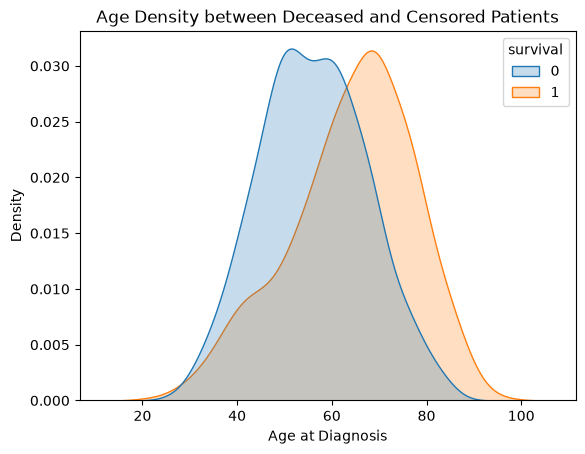

In [27]:
sns.kdeplot(data=filtered_mb, x="Age at Diagnosis", hue="survival", fill=True, common_norm=False)
plt.title("Age Density between Deceased and Censored Patients")
plt.show()


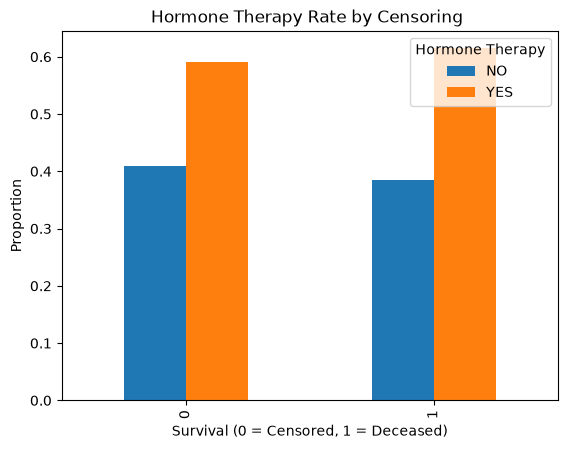

In [28]:
therapy_by_status = filtered_mb.groupby("survival")["Hormone Therapy"].value_counts(normalize=True).unstack()

therapy_by_status.plot(kind="bar", stacked=False)
plt.title("Hormone Therapy Rate by Censoring ")
plt.ylabel("Proportion")
plt.xlabel("Survival (0 = Censored, 1 = Deceased)")
plt.show()